# Kepler KOI — Preprocessing + EDA-Driven Feature Selection
**Dataset:** NASA Exoplanet Archive — Cumulative KOI Table  
**Goal:** Classify each KOI as `CONFIRMED`, `CANDIDATE`, or `FALSE POSITIVE`

### Workflow
1. Load & initial cleanup  
2. EDA — distributions, class separation, correlation  
3. EDA — Random Forest feature importance  
4. Feature selection based on EDA findings  
5. Encode, impute, scale  
6. Save final preprocessed file


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 60)


## 1. Load Data

In [2]:
FILE_PATH = "1779873785378_cumulative_2026_05_06_12_44_09.csv"

df_raw = pd.read_csv(FILE_PATH, comment="#")
print(f"Shape: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns")
df_raw.head(3)


Shape: 9564 rows × 49 columns


,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_period,koi_period_err1,koi_period_err2,koi_time0bk,koi_time0bk_err1,koi_time0bk_err2,koi_impact,koi_impact_err1,koi_impact_err2,koi_duration,koi_duration_err1,koi_duration_err2,koi_depth,koi_depth_err1,koi_depth_err2,koi_prad,koi_prad_err1,koi_prad_err2,koi_teq,koi_teq_err1,koi_teq_err2,koi_insol,koi_insol_err1,koi_insol_err2,koi_model_snr,koi_tce_plnt_num,koi_tce_delivname,koi_steff,koi_steff_err1,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,9.488036,0.000028,-0.000028,170.538750,0.002160,-0.002160,0.146,0.318,-0.146,2.9575,0.0819,-0.0819,615.8,19.5,-19.5,2.26,0.26,-0.15,793.0,NaN,NaN,93.59,29.45,-16.65,35.8,1.0,q1_q17_dr25_tce,5455.0,81.0,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,0,54.418383,0.000248,-0.000248,162.513840,0.003520,-0.003520,0.586,0.059,-0.443,4.5070,0.1160,-0.1160,874.8,35.5,-35.5,2.83,0.32,-0.19,443.0,NaN,NaN,9.11,2.87,-1.62,25.8,2.0,q1_q17_dr25_tce,5455.0,81.0,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,10811496,K00753.01,NaN,CANDIDATE,CANDIDATE,0.000,0,0,0,0,19.899140,0.000015,-0.000015,175.850252,0.000581,-0.000581,0.969,5.126,-0.077,1.7822,0.0341,-0.0341,10829.0,171.0,-171.0,14.60,3.92,-1.31,638.0,NaN,NaN,39.30,31.04,-10.49,76.3,1.0,q1_q17_dr25_tce,5853.0,158.0,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436


## 2. Initial Cleanup
Drop columns that are always null or are pure identifiers/labels with no predictive value.

In [3]:
df = df_raw.copy()

# Always-null columns
always_null = [c for c in df.columns if df[c].isnull().all()]
print(f"Always-null columns dropped: {always_null}")
df.drop(columns=always_null, inplace=True)

# Non-feature columns (identifiers, pipeline labels, raw name strings)
non_features = ["kepoi_name", "kepler_name", "koi_tce_delivname", "kepid"]
df.drop(columns=non_features, inplace=True)

print(f"Shape after cleanup: {df.shape}")


Always-null columns dropped: ['koi_teq_err1', 'koi_teq_err2']
Shape after cleanup: (9564, 43)


## 3. EDA — Missing Values
Features with high missingness before imputation may be unreliable.

In [4]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"missing_count": missing, "missing_%": missing_pct})
missing_df = missing_df[missing_df["missing_count"] > 0].sort_values("missing_%", ascending=False)

print(missing_df.to_string())


                   missing_count  missing_%
koi_score                   1510      15.79
koi_steff_err2               483       5.05
koi_srad_err2                468       4.89
koi_slogg_err1               468       4.89
koi_slogg_err2               468       4.89
koi_srad_err1                468       4.89
koi_steff_err1               468       4.89
koi_period_err1              454       4.75
koi_depth_err1               454       4.75
koi_duration_err2            454       4.75
koi_period_err2              454       4.75
koi_time0bk_err1             454       4.75
koi_time0bk_err2             454       4.75
koi_impact_err1              454       4.75
koi_impact_err2              454       4.75
koi_duration_err1            454       4.75
koi_depth_err2               454       4.75
koi_prad_err2                363       3.80
koi_prad                     363       3.80
koi_depth                    363       3.80
koi_impact                   363       3.80
koi_prad_err1                363

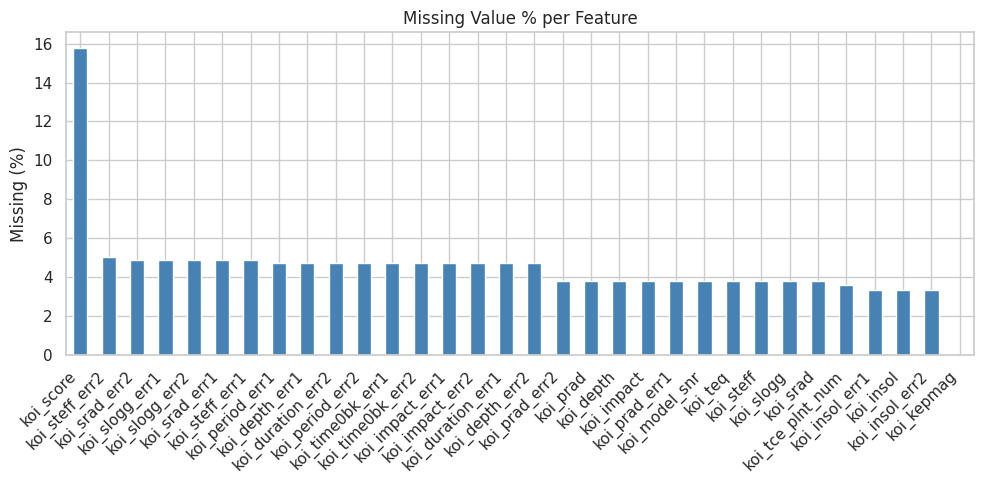

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
missing_df["missing_%"].plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Missing Value % per Feature")
ax.set_ylabel("Missing (%)")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 4. EDA — Target Class Distribution

/tmp/ipykernel_530/3586190258.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, order=order, palette="Set2", ax=ax)


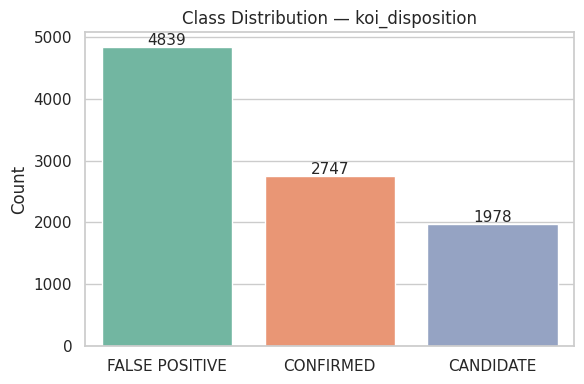

koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2747
CANDIDATE         1978
Name: count, dtype: int64


In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
order = ["FALSE POSITIVE", "CONFIRMED", "CANDIDATE"]
counts = df["koi_disposition"].value_counts()
sns.barplot(x=counts.index, y=counts.values, order=order, palette="Set2", ax=ax)
for i, v in enumerate(counts.reindex(order).values):
    ax.text(i, v + 30, str(v), ha="center", fontsize=11)
ax.set_title("Class Distribution — koi_disposition")
ax.set_ylabel("Count")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

print(counts)


## 5. EDA — Encode Target
Encode target temporarily for correlation and importance analysis.

In [7]:
disposition_map = {"CONFIRMED": 2, "CANDIDATE": 1, "FALSE POSITIVE": 0}
df["target"] = df["koi_disposition"].map(disposition_map)

# Also drop koi_pdisposition — it's a leaky preliminary version of the target
df.drop(columns=["koi_disposition", "koi_pdisposition"], inplace=True)


## 6. EDA — Correlation with Target
Higher absolute correlation = stronger linear relationship with the label.

In [8]:
numeric_df = df.select_dtypes(include="number")

# Temporarily impute for correlation (median)
numeric_imputed = numeric_df.fillna(numeric_df.median())

corr_with_target = (
    numeric_imputed.corr()["target"]
    .drop("target")
    .abs()
    .sort_values(ascending=False)
)

print("Top 20 features by absolute correlation with target:")
print(corr_with_target.head(20).round(3).to_string())


Top 20 features by absolute correlation with target:
koi_score            0.862
koi_fpflag_ss        0.490
koi_fpflag_co        0.449
koi_steff_err1       0.393
koi_steff_err2       0.347
koi_fpflag_ec        0.334
koi_teq              0.268
koi_depth            0.244
koi_slogg_err2       0.240
koi_tce_plnt_num     0.223
koi_model_snr        0.214
koi_steff            0.204
koi_duration         0.154
koi_slogg            0.154
ra                   0.153
koi_slogg_err1       0.148
koi_duration_err2    0.141
koi_duration_err1    0.141
koi_srad_err1        0.129
koi_impact_err1      0.117


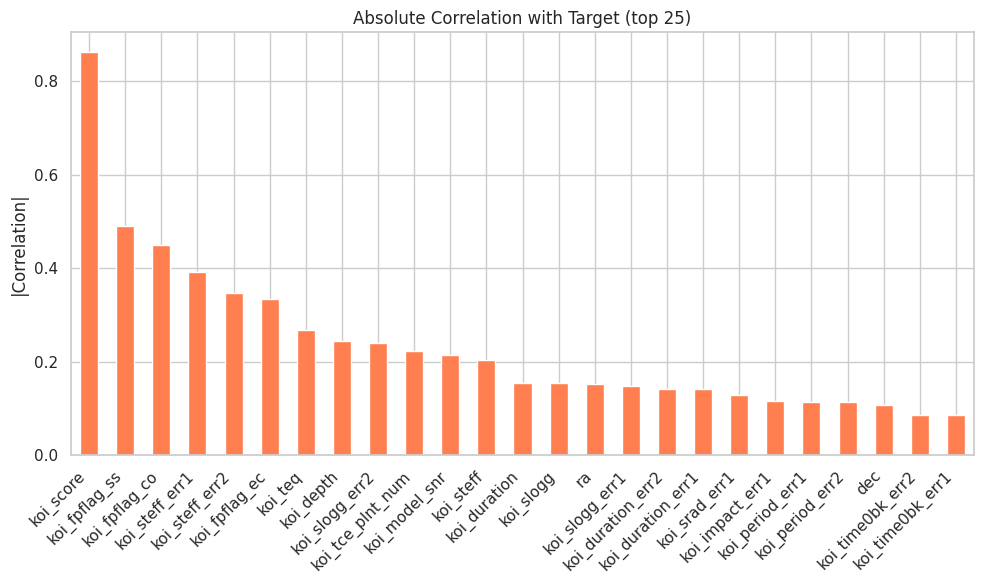

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
corr_with_target.head(25).plot(kind="bar", ax=ax, color="coral")
ax.set_title("Absolute Correlation with Target (top 25)")
ax.set_ylabel("|Correlation|")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 7. EDA — Class Separation Boxplots
Visualise how well each top feature separates the three classes.

/tmp/ipykernel_530/3788454977.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_530/3788454977.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_530/3788454977.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_530/3788454977.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


/tmp/ipykernel_530/3788454977.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_530/3788454977.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_530/3788454977.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_530/3788454977.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


/tmp/ipykernel_530/3788454977.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_530/3788454977.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_530/3788454977.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_530/3788454977.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


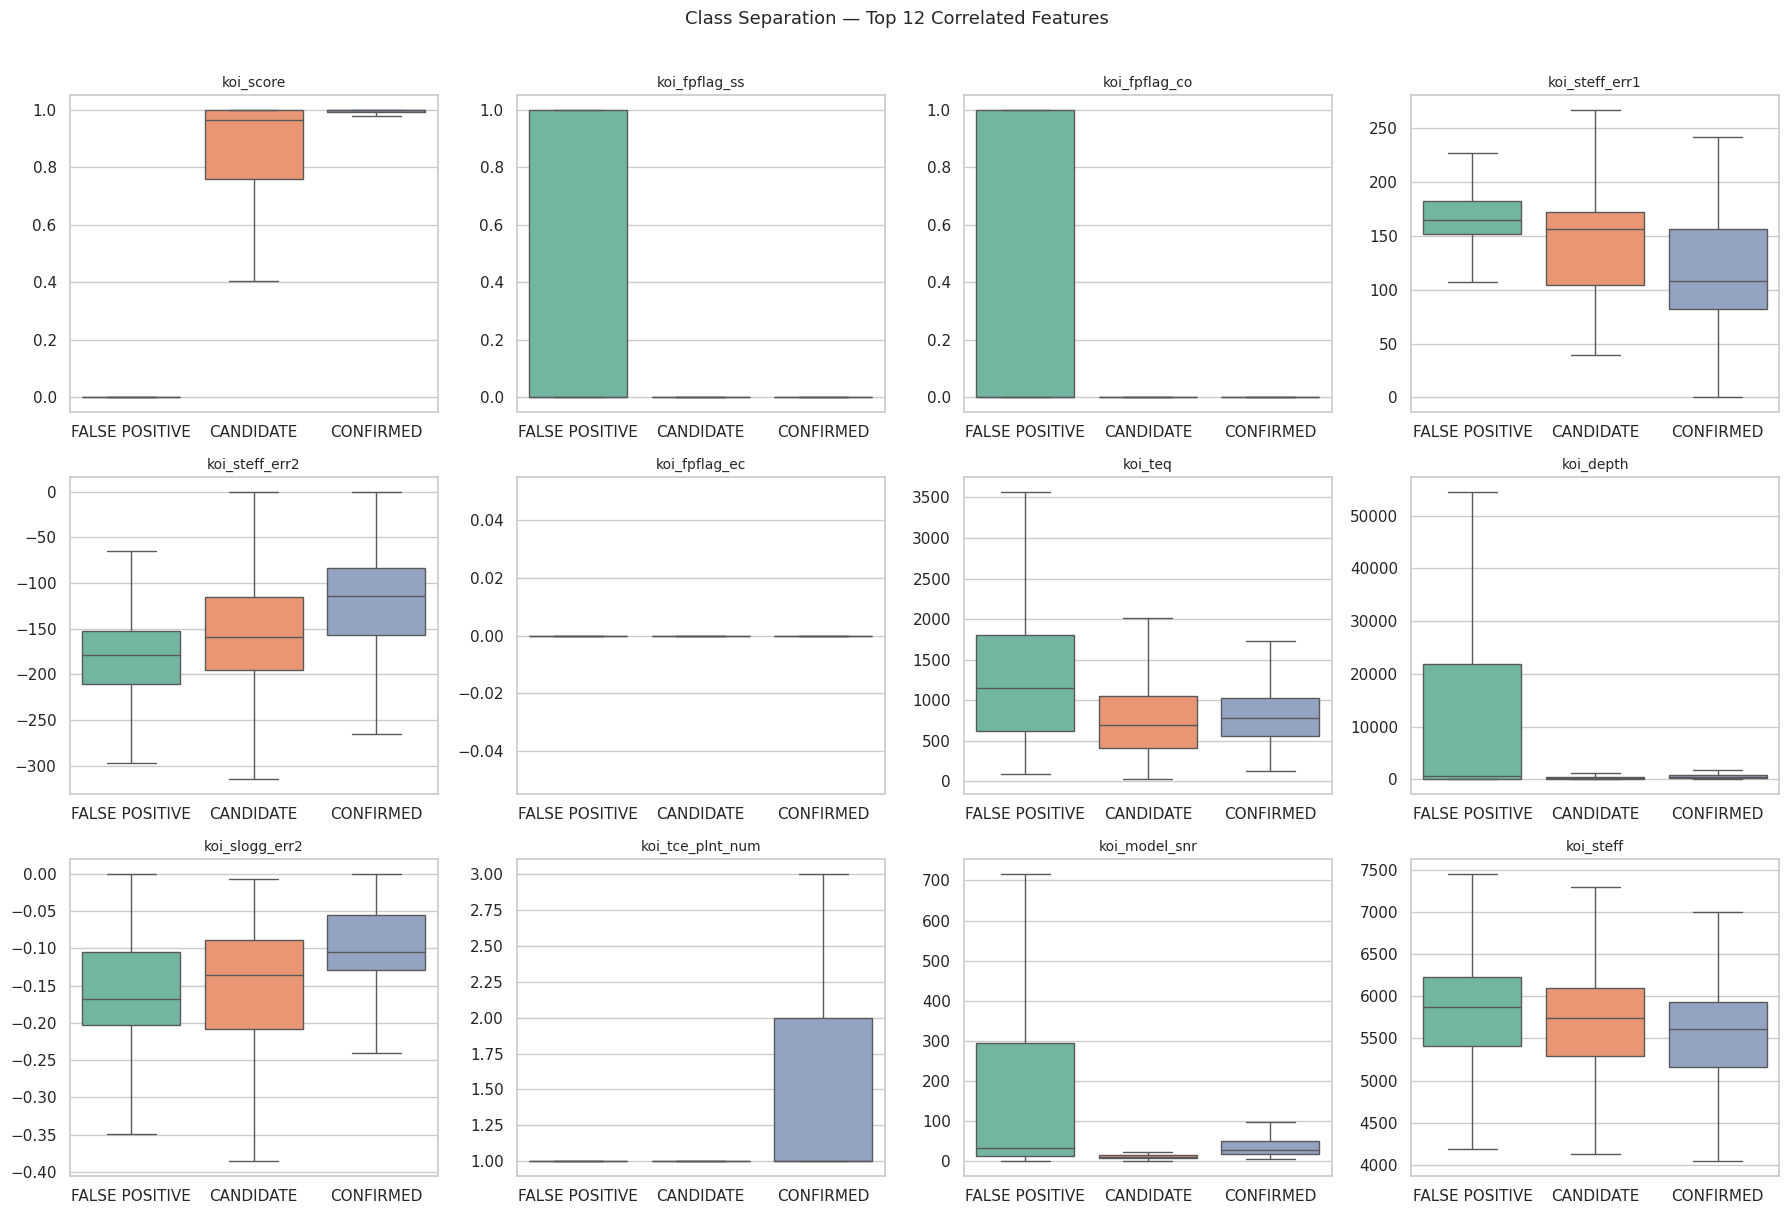

In [10]:
top_features = corr_with_target.head(12).index.tolist()

# Reconstruct disposition label for plotting
df["koi_disposition"] = df["target"].map({2: "CONFIRMED", 1: "CANDIDATE", 0: "FALSE POSITIVE"})

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, feat in enumerate(top_features):
    sns.boxplot(
        data=df, x="koi_disposition", y=feat,
        order=["FALSE POSITIVE", "CANDIDATE", "CONFIRMED"],
        palette="Set2", ax=axes[i], showfliers=False
    )
    axes[i].set_title(feat, fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

plt.suptitle("Class Separation — Top 12 Correlated Features", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

df.drop(columns=["koi_disposition"], inplace=True)  # clean up temp column


## 8. EDA — Random Forest Feature Importance
A quick RF (no tuning) gives a model-based importance ranking independent of linear assumptions.

In [11]:
X_eda = numeric_imputed.drop(columns=["target"])
y_eda = numeric_imputed["target"]

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_eda, y_eda)

importances = pd.Series(rf.feature_importances_, index=X_eda.columns)
importances = importances.sort_values(ascending=False)

print("Top 20 features by RF importance:")
print(importances.head(20).round(4).to_string())


Top 20 features by RF importance:
koi_score            0.1995
koi_fpflag_nt        0.0936
koi_fpflag_ss        0.0672
koi_fpflag_co        0.0636
koi_model_snr        0.0510
koi_prad             0.0472
koi_duration_err2    0.0318
koi_duration_err1    0.0316
koi_steff_err2       0.0258
koi_steff_err1       0.0251
koi_time0bk_err2     0.0238
koi_prad_err1        0.0222
koi_fpflag_ec        0.0206
koi_period           0.0204
koi_time0bk_err1     0.0192
koi_duration         0.0177
koi_depth            0.0165
koi_prad_err2        0.0165
koi_insol_err1       0.0138
koi_period_err1      0.0138


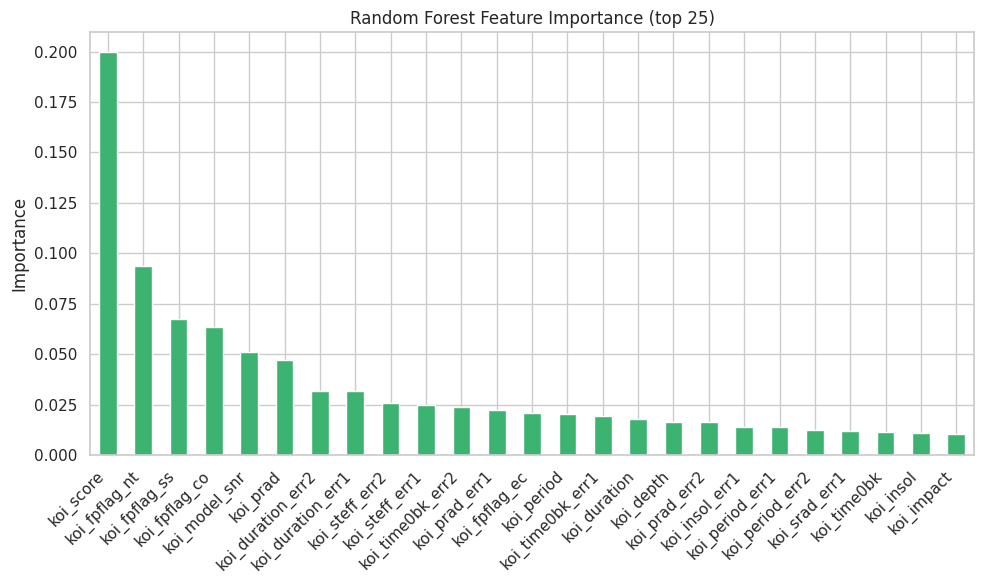

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
importances.head(25).plot(kind="bar", ax=ax, color="mediumseagreen")
ax.set_title("Random Forest Feature Importance (top 25)")
ax.set_ylabel("Importance")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 9. Combined Ranking — Correlation + RF Importance
Normalise both scores and average them to get a consensus ranking.

In [13]:
corr_norm = corr_with_target / corr_with_target.max()
imp_norm  = importances / importances.max()

combined = pd.DataFrame({
    "corr_norm": corr_norm,
    "imp_norm":  imp_norm
}).dropna()

combined["combined_score"] = combined.mean(axis=1)
combined = combined.sort_values("combined_score", ascending=False)

print("Top 20 features by combined score:")
print(combined.head(20).round(3).to_string())


Top 20 features by combined score:
                   corr_norm  imp_norm  combined_score
koi_score              1.000     1.000           1.000
koi_fpflag_ss          0.569     0.337           0.453
koi_fpflag_co          0.521     0.319           0.420
koi_steff_err1         0.456     0.126           0.291
koi_steff_err2         0.403     0.129           0.266
koi_model_snr          0.249     0.256           0.252
koi_fpflag_ec          0.388     0.103           0.246
koi_fpflag_nt          0.018     0.469           0.244
koi_depth              0.283     0.083           0.183
koi_teq                0.311     0.042           0.177
koi_slogg_err2         0.278     0.051           0.165
koi_duration_err2      0.163     0.160           0.161
koi_duration_err1      0.163     0.159           0.161
koi_steff              0.237     0.037           0.137
koi_tce_plnt_num       0.259     0.013           0.136
koi_duration           0.179     0.089           0.134
koi_prad               0.025  

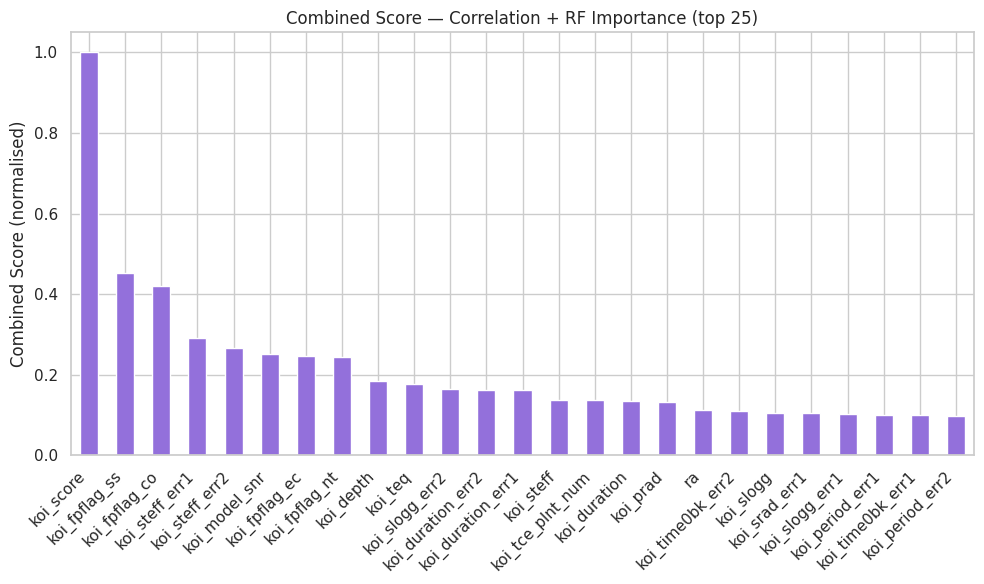

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
combined["combined_score"].head(25).plot(kind="bar", ax=ax, color="mediumpurple")
ax.set_title("Combined Score — Correlation + RF Importance (top 25)")
ax.set_ylabel("Combined Score (normalised)")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 10. Feature Selection
Select features based on the combined EDA score (correlation + RF importance).

**Rules applied:**
- Keep features with combined score ≥ **0.07**
- Drop all `_err1` / `_err2` error columns — low independent signal
- Manually drop `ra`, `dec`, `koi_tce_plnt_num` — non-causal / pipeline artifacts
- Manually add back `koi_period`, `koi_impact`, `koi_insol`, `koi_srad` — physically meaningful features that scored just below threshold (0.05–0.06) but are core transit/planetary descriptors


In [15]:
THRESHOLD = 0.07

# Select by combined EDA score
selected = combined[combined["combined_score"] >= THRESHOLD].index.tolist()

# Remove error/uncertainty columns — low independent signal beyond their parent feature
selected = [f for f in selected if "_err" not in f]

# Remove non-causal / pipeline artifact features
manually_drop = ["ra", "dec", "koi_tce_plnt_num"]
selected = [f for f in selected if f not in manually_drop]
print(f"Dropped non-causal features: {manually_drop}")

# Manually add back physically meaningful features that scored just below threshold
# koi_period (0.055), koi_impact (0.063), koi_insol (0.051), koi_srad (0.059)
# These are core transit/planetary features with clear physical relevance
manually_add = ["koi_period", "koi_impact", "koi_insol", "koi_srad"]
for f in manually_add:
    if f not in selected:
        selected.append(f)
print(f"Manually added back physically meaningful features: {manually_add}")

print(f"\nFinal selected features ({len(selected)}):")
for f in selected:
    score = combined.loc[f, "combined_score"] if f in combined.index else "manual"
    print(f"  {f:<20} score: {round(score, 3) if isinstance(score, float) else score}")


Dropped non-causal features: ['ra', 'dec', 'koi_tce_plnt_num']
Manually added back physically meaningful features: ['koi_period', 'koi_impact', 'koi_insol', 'koi_srad']

Final selected features (16):
  koi_score            score: 1.0
  koi_fpflag_ss        score: 0.453
  koi_fpflag_co        score: 0.42
  koi_model_snr        score: 0.252
  koi_fpflag_ec        score: 0.246
  koi_fpflag_nt        score: 0.244
  koi_depth            score: 0.183
  koi_teq              score: 0.177
  koi_steff            score: 0.137
  koi_duration         score: 0.134
  koi_prad             score: 0.131
  koi_slogg            score: 0.105
  koi_period           score: 0.055
  koi_impact           score: 0.063
  koi_insol            score: 0.051
  koi_srad             score: 0.059


## 11. Final Preprocessing on Selected Features

In [16]:
# Rebuild from raw data using only selected features + target
df_final = df_raw.copy()

# Drop always-null + non-feature columns
df_final.drop(columns=always_null + non_features, inplace=True, errors="ignore")

# Encode target
df_final["target"] = df_final["koi_disposition"].map(disposition_map)
df_final.drop(columns=["koi_disposition", "koi_pdisposition", "koi_pdisposition_encoded"],
              inplace=True, errors="ignore")

# Keep only selected features
cols_available = [c for c in selected if c in df_final.columns]
X = df_final[cols_available].copy()
y = df_final["target"].copy()

print(f"Feature matrix: {X.shape}")
print(f"Target: {y.shape}")
print(f"Class distribution:\n{y.value_counts().rename({2:'CONFIRMED',1:'CANDIDATE',0:'FALSE POSITIVE'})}")


Feature matrix: (9564, 16)
Target: (9564,)
Class distribution:
target
FALSE POSITIVE    4839
CONFIRMED         2747
CANDIDATE         1978
Name: count, dtype: int64


In [17]:
# Impute missing values with median
for col in X.columns:
    if X[col].isnull().sum() > 0:
        X[col] = X[col].fillna(X[col].median())

print("Missing values after imputation:", X.isnull().sum().sum())

# ── Fix binary flag anomalies ──────────────────────────────────────────────
# koi_fpflag_* should only be 0 or 1; clip any erroneous values (e.g. 465)
flag_cols = ["koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"]
flag_cols_present = [f for f in flag_cols if f in X.columns]

for col in flag_cols_present:
    anomalies = X[~X[col].isin([0, 1])]
    if len(anomalies) > 0:
        print(f"  Fixed {len(anomalies)} anomalous value(s) in {col}: {anomalies[col].values} → clipped to 1")
    X[col] = X[col].clip(0, 1).round().astype(int)

print(f"Flag columns clipped to binary (0/1): {flag_cols_present}")


Missing values after imputation: 0
  Fixed 1 anomalous value(s) in koi_fpflag_nt: [465] → clipped to 1
Flag columns clipped to binary (0/1): ['koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec']


In [18]:
# Scale only continuous features — binary flags are already on 0/1 scale
# and should NOT be standardised (scaling distorts their binary meaning)
flag_cols = ["koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"]
flag_cols_present  = [f for f in flag_cols if f in X.columns]
continuous_cols    = [c for c in X.columns if c not in flag_cols_present]

scaler = StandardScaler()
X_continuous_scaled = pd.DataFrame(
    scaler.fit_transform(X[continuous_cols]),
    columns=continuous_cols,
    index=X.index
)

# Rejoin unscaled flags
X_scaled = pd.concat([X_continuous_scaled, X[flag_cols_present]], axis=1)
# Restore original column order
X_scaled = X_scaled[X.columns]

print(f"Scaled {len(continuous_cols)} continuous features: {continuous_cols}")
print(f"Left unscaled {len(flag_cols_present)} binary flag features: {flag_cols_present}")
print(f"\nSample means of continuous cols (~0): {X_scaled[continuous_cols].mean().round(4).values[:4]}")
print(f"Sample stds  of continuous cols (~1): {X_scaled[continuous_cols].std().round(4).values[:4]}")
print(f"\nFlag value counts after clipping:")
for col in flag_cols_present:
    print(f"  {col}: {dict(X_scaled[col].value_counts().sort_index())}")


Scaled 12 continuous features: ['koi_score', 'koi_model_snr', 'koi_depth', 'koi_teq', 'koi_steff', 'koi_duration', 'koi_prad', 'koi_slogg', 'koi_period', 'koi_impact', 'koi_insol', 'koi_srad']
Left unscaled 4 binary flag features: ['koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec']

Sample means of continuous cols (~0): [-0.  0.  0.  0.]
Sample stds  of continuous cols (~1): [1.0001 1.0001 1.0001 1.0001]

Flag value counts after clipping:
  koi_fpflag_nt: {0: np.int64(8033), 1: np.int64(1531)}
  koi_fpflag_ss: {0: np.int64(7338), 1: np.int64(2226)}
  koi_fpflag_co: {0: np.int64(7675), 1: np.int64(1889)}
  koi_fpflag_ec: {0: np.int64(8416), 1: np.int64(1148)}


## 12. Save Preprocessed Data
Two versions are saved — scaled for distance-based models, unscaled for tree-based models.

In [19]:
# --- Scaled output (for SVM / KNN / Logistic Regression / Neural Nets) ---
output_scaled = X_scaled.copy()
output_scaled["target"] = y.values
output_scaled.to_csv("preprocessed_scaled.csv", index=False)
print(f"Saved preprocessed_scaled.csv   — {output_scaled.shape[0]} rows × {output_scaled.shape[1]} columns")
print("  → Use with: SVM, KNN, Logistic Regression, Neural Nets")

# --- Unscaled output (for Random Forest / XGBoost / Decision Trees) ---
output_unscaled = X.copy()
output_unscaled["target"] = y.values
output_unscaled.to_csv("preprocessed_unscaled.csv", index=False)
print(f"\nSaved preprocessed_unscaled.csv — {output_unscaled.shape[0]} rows × {output_unscaled.shape[1]} columns")
print("  → Use with: Random Forest, XGBoost, Decision Tree")

print("\nDone.")


Saved preprocessed_scaled.csv   — 9564 rows × 17 columns
  → Use with: SVM, KNN, Logistic Regression, Neural Nets

Saved preprocessed_unscaled.csv — 9564 rows × 17 columns
  → Use with: Random Forest, XGBoost, Decision Tree

Done.
